# Lab_Product_Launch — Motor Monte Carlo (MVP)

Este notebook implementa a **spec 001** (`specs/001-motor-monte-carlo/spec.md`):
uma ideia de negócio entra como ficha estruturada, o motor simula 10.000 versões
do negócio por 24 meses e devolve **Go / Pivot / Kill** com probabilidades.

**Dois modos**

| Modo | Dados | Quando usar |
|---|---|---|
| `demo` | Valores ilustrativos e base de CNPJs **sintética** | Ver o motor funcionando agora |
| `bigquery` | Base dos Dados: CNPJ (Receita), RAIS, população (IBGE) | Na sua máquina, com projeto Google Cloud |

> Os números do modo `demo` **não são de nenhuma cidade real**. Servem para mostrar o método.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lab.engine import Premissa as P, FichaIdeia, simular, para_llm, kaplan_meier, sobrevivencia_em
from lab import dados

MODO = 'demo'               # 'demo' ou 'bigquery'
BILLING_PROJECT = 'seu-projeto-gcp'
UF = 'AL'
ID_MUNICIPIO = '2704302'    # Maceió (código IBGE); troque pela cidade da ideia

# CNAEs de teste — confirme os códigos na CONCLA/IBGE
CNAES = {
    'sorveteria': '5611203',   # lanchonetes, casas de chá, de sucos e similares
    'salao':      '9602501',   # cabeleireiros, manicure e pedicure
    'agencia':    '7311400',   # agências de publicidade
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def brl(v):  # R$ no formato brasileiro
    return 'R$ ' + f'{v:,.0f}'.replace(',', '.')
def rotulo(ficha, k):
    return ficha.premissas[k].nome if k in ficha.premissas else k.replace('_', ' ')

## 1. A história do setor: sobrevivência pela base de CNPJs

Cada estabelecimento tem data de abertura e, se fechou, data da baixa ou inaptidão.
Com isso a curva de Kaplan-Meier responde: **quantos negócios desse tipo continuam
abertos depois de 1, 2 e 5 anos?** Esse é o ponto de partida antes de olhar a ideia.

In [2]:
def base_cnpj(nome):
    if MODO == 'bigquery':
        sql = dados.SQL_ESTABELECIMENTOS.format(uf=UF, cnae=CNAES[nome])
        return dados.preparar_cnpj(dados.consultar(sql, BILLING_PROJECT))
    # SINTÉTICO: sobrevivência de 2 anos escolhida só para demonstração
    sobrev_demo = {'sorveteria': 0.55, 'salao': 0.50, 'agencia': 0.62}
    return dados.cnpj_sintetico(800, sobrev_demo[nome], seed=len(nome))

curvas, resumo = {}, []
for nome in CNAES:
    df = base_cnpj(nome)
    curva = kaplan_meier(df)
    curvas[nome] = curva
    resumo.append({'setor': nome, 'estabelecimentos': len(df),
                   'ativos hoje': int(df['ativa'].sum()),
                   'sobrevivência 1 ano': sobrevivencia_em(curva, 12),
                   'sobrevivência 2 anos': sobrevivencia_em(curva, 24),
                   'sobrevivência 5 anos': sobrevivencia_em(curva, 60)})
resumo = pd.DataFrame(resumo).set_index('setor')
resumo.style.format({c: '{:.0%}' for c in resumo.columns if 'sobrev' in c})

,estabelecimentos,ativos hoje,sobrevivência 1 ano,sobrevivência 2 anos,sobrevivência 5 anos
setor,,,,,
sorveteria,800,213,75%,53%,25%
salao,800,192,71%,49%,19%
agencia,800,278,78%,63%,31%


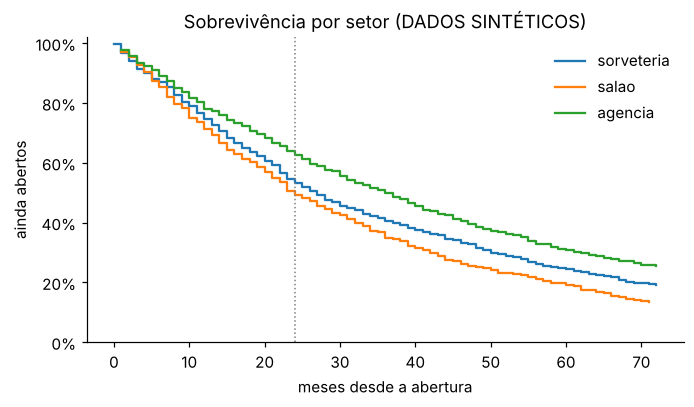

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for nome, c in curvas.items():
    c = c[c['mes'] <= 72]
    ax.step(c['mes'], c['sobrevivencia'], where='post', label=nome)
ax.axvline(24, color='gray', ls=':', lw=1)
ax.set(xlabel='meses desde a abertura', ylabel='ainda abertos', ylim=(0, 1.02),
       title='Sobrevivência por setor' + (' (DADOS SINTÉTICOS)' if MODO == 'demo' else ''))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); plt.show()

## 2. A ficha da ideia: sorveteria (arquétipo varejo de fluxo)

Cada premissa é uma **faixa** (mínimo, provável, máximo) com a sua fonte.
Clientes por dia não é chute: sai de **domicílios no raio × gasto mensal por
domicílio na categoria × fatia de mercado**, e a fatia depende do número de
concorrentes ativos na base de CNPJs.

In [4]:
if MODO == 'bigquery':
    pop = dados.consultar(dados.SQL_POPULACAO.format(id_municipio=ID_MUNICIPIO), BILLING_PROJECT)
    domicilios_cidade = float(pop['populacao'].iloc[0]) / dados.MORADORES_POR_DOMICILIO
    # MVP: fração da cidade no raio de atuação (refinar com setores censitários)
    domicilios_raio = domicilios_cidade * 0.05
else:
    domicilios_raio = 9_000   # ilustrativo

concorrentes_raio = 12        # modo real: contar CNPJs ativos do CNAE por CEP/raio

base = dict(
    margem_bruta    = P('margem bruta', .55, .62, .68, 'referência do setor (curada)'),
    reserva_caixa   = P('reserva de caixa', 10e3, 15e3, 20e3, 'usuário'),
    meses_rampa     = P('meses até maturar', 6, 9, 12, 'referência'),
)
sorveteria = FichaIdeia(
    texto='Quero abrir uma sorveteria com mesas, perto do centro',
    cnae=CNAES['sorveteria'], municipio=f'{ID_MUNICIPIO} ({UF})', arquetipo='fluxo',
    concorrentes=concorrentes_raio,
    sobrevivencia_2a_setor=resumo.loc['sorveteria', 'sobrevivência 2 anos'],
    cobertura_dados=0.5,
    premissas={**base,
        'domicilios_raio':     P('domicílios no raio', domicilios_raio, domicilios_raio, domicilios_raio, 'Censo 2022 / IBGE', 'fixo'),
        'gasto_domicilio_mes': P('gasto por domicílio (R$/mês)', 15, 25, 40, 'POF/IBGE ajustada pela renda local'),
        'ticket':              P('ticket médio (R$)', 13, 16, 20, 'usuário'),
        'custo_fixo_mes':      P('custo fixo (R$/mês)', 7_000, 9_000, 12_000, 'usuário (aluguel) + RAIS (salários)'),
        'investimento':        P('investimento inicial (R$)', 60e3, 75e3, 95e3, 'usuário'),
    })
r = simular(sorveteria)
print('DECISÃO:', r.decisao, '| confiança:', r.confianca)
pd.Series(r.metricas).to_frame('valor')

DECISÃO: KILL | confiança: média


,valor
lucro_mensal_p10,-5264.979080
lucro_mensal_p50,749.261694
lucro_mensal_p90,11142.436814
p_payback_12m,0.113400
p_payback_24m,0.290100
p_caixa_acabar,0.542400
caixa_esperado_m24,-55825.348286
receita_mensal_p50,16324.408159
clientes_dia_p50,38.425766


## 3. O que as 10.000 simulações mostram

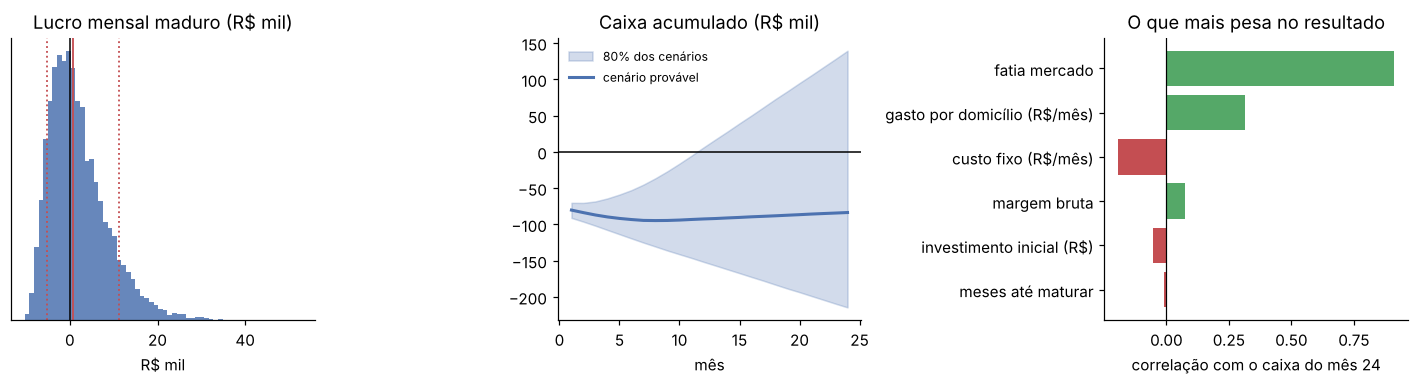

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# a) lucro mensal depois de maturar
lm = r.caixa[:, -1] - r.caixa[:, -2]
ax = axes[0]
ax.hist(lm / 1e3, bins=60, color='#4C72B0', alpha=.85)
ax.axvline(0, color='black', lw=1)
for q, ls in [(10, ':'), (50, '-'), (90, ':')]:
    ax.axvline(np.percentile(lm, q) / 1e3, color='#C44E52', ls=ls, lw=1.2)
ax.set(title='Lucro mensal maduro (R$ mil)', xlabel='R$ mil', yticks=[])

# b) caixa acumulado: faixa p10–p90 e mediana
ax = axes[1]
meses = np.arange(1, r.caixa.shape[1] + 1)
p10, p50, p90 = np.percentile(r.caixa, [10, 50, 90], axis=0) / 1e3
ax.fill_between(meses, p10, p90, color='#4C72B0', alpha=.25, label='80% dos cenários')
ax.plot(meses, p50, color='#4C72B0', lw=2, label='cenário provável')
ax.axhline(0, color='black', lw=1)
ax.set(title='Caixa acumulado (R$ mil)', xlabel='mês'); ax.legend(frameon=False, fontsize=8)

# c) o que mais pesa
ax = axes[2]
s = r.sensibilidade.head(6)[::-1]
ax.barh([rotulo(sorveteria, k) for k in s.index], s.values, color=np.where(s.values > 0, '#55A868', '#C44E52'))
ax.axvline(0, color='black', lw=.8)
ax.set(title='O que mais pesa no resultado', xlabel='correlação com o caixa do mês 24')
plt.tight_layout(); plt.show()

## 4. Pivot: e se for um quiosque?

O que mais pesa é a fatia de mercado, ou seja, quantos clientes a loja conquista.
Com essa demanda, a loja grande não se paga. A variante testa um quiosque: mesma
demanda, custo fixo e investimento menores.

In [6]:
quiosque = FichaIdeia(**{**sorveteria.__dict__,
    'texto': 'Variante: quiosque de sorvete e açaí',
    'premissas': {**sorveteria.premissas,
        'custo_fixo_mes': P('custo fixo (R$/mês)', 3_500, 4_500, 6_000, 'usuário'),
        'investimento':   P('investimento inicial (R$)', 30e3, 38e3, 48e3, 'usuário')}})
rq = simular(quiosque)

comp = pd.DataFrame({'Loja': r.metricas, 'Quiosque': rq.metricas}).T
comp.insert(0, 'decisão', [r.decisao, rq.decisao])
cols = ['decisão', 'lucro_mensal_p10', 'lucro_mensal_p50', 'lucro_mensal_p90',
        'p_payback_12m', 'p_payback_24m', 'p_caixa_acabar']
comp[cols].style.format({c: brl for c in cols if 'lucro' in c} |
                        {c: '{:.0%}' for c in cols if c.startswith('p_')})

,decisão,lucro_mensal_p10,lucro_mensal_p50,lucro_mensal_p90,p_payback_12m,p_payback_24m,p_caixa_acabar
Loja,KILL,R$ -5.265,R$ 749,R$ 11.142,11%,29%,54%
Quiosque,GO,R$ -490,R$ 5.377,R$ 15.718,50%,71%,12%


## 5. Mesmo motor, outras ideias

Salão de beleza (arquétipo **capacidade**) e agência de marketing (arquétipo
**B2B recorrente**). Só muda a ficha; o código é o mesmo.

In [7]:
salao = FichaIdeia(
    texto='Salão de beleza com 4 cadeiras', cnae=CNAES['salao'],
    municipio=f'{ID_MUNICIPIO} ({UF})', arquetipo='capacidade',
    sobrevivencia_2a_setor=resumo.loc['salao', 'sobrevivência 2 anos'], cobertura_dados=0.4,
    premissas={
        'estacoes':                 P('cadeiras', 4, 4, 4, 'usuário', 'fixo'),
        'atendimentos_estacao_dia': P('atendimentos por cadeira/dia', 5, 7, 9, 'referência'),
        'ocupacao':                 P('ocupação da agenda', .4, .6, .8, 'referência'),
        'ticket':                   P('ticket médio (R$)', 40, 60, 90, 'usuário'),
        'margem_bruta':             P('margem após comissões', .45, .55, .65, 'referência'),
        'custo_fixo_mes':           P('custo fixo (R$/mês)', 6e3, 8e3, 11e3, 'usuário + RAIS'),
        'investimento':             P('investimento (R$)', 40e3, 55e3, 75e3, 'usuário'),
        'reserva_caixa':            P('reserva (R$)', 10e3, 15e3, 20e3, 'usuário'),
        'meses_rampa':              P('meses até maturar', 4, 6, 9, 'referência')})

agencia = FichaIdeia(
    texto='Agência de marketing digital para PMEs', cnae=CNAES['agencia'],
    municipio=f'{ID_MUNICIPIO} ({UF})', arquetipo='b2b',
    sobrevivencia_2a_setor=resumo.loc['agencia', 'sobrevivência 2 anos'], cobertura_dados=0.3,
    premissas={
        'novos_clientes_mes':  P('novos clientes por mês', .3, .7, 1.5, 'referência'),
        'churn_mensal':        P('cancelamento mensal', .04, .06, .10, 'referência'),
        'capacidade_clientes': P('clientes que a equipe atende', 8, 12, 15, 'usuário'),
        'mensalidade':         P('mensalidade (R$)', 1500, 2500, 4000, 'usuário'),
        'margem_bruta':        P('margem bruta', .5, .6, .7, 'referência'),
        'custo_fixo_mes':      P('custo fixo (R$/mês)', 5e3, 7e3, 10e3, 'usuário'),
        'investimento':        P('investimento (R$)', 15e3, 25e3, 40e3, 'usuário'),
        'reserva_caixa':       P('reserva (R$)', 10e3, 20e3, 30e3, 'usuário'),
        'meses_rampa':         P('meses até maturar', 9, 12, 18, 'referência'),
        'rampa_inicio':        P('fração da carteira no mês 1', .05, .1, .2, 'referência')})

linhas = []
for nome, f in [('Sorveteria (loja)', sorveteria), ('Sorveteria (quiosque)', quiosque),
                ('Salão de beleza', salao), ('Agência de marketing', agencia)]:
    res = simular(f)
    linhas.append({'ideia': nome, 'arquétipo': f.arquetipo, 'decisão': res.decisao,
                   'lucro provável/mês': res.metricas['lucro_mensal_p50'],
                   'paga em 24 meses': res.metricas['p_payback_24m'],
                   'caixa acaba': res.metricas['p_caixa_acabar'],
                   'sobrevivência 2a do setor': f.sobrevivencia_2a_setor,
                   'alerta': '; '.join(res.alertas) or '—', 'confiança': res.confianca})
tabela = pd.DataFrame(linhas).set_index('ideia')
tabela.style.format({'lucro provável/mês': brl, 'paga em 24 meses': '{:.0%}',
                     'caixa acaba': '{:.0%}', 'sobrevivência 2a do setor': '{:.0%}'})

,arquétipo,decisão,lucro provável/mês,paga em 24 meses,caixa acaba,sobrevivência 2a do setor,alerta,confiança
ideia,,,,,,,,
Sorveteria (loja),fluxo,KILL,R$ 749,29%,54%,53%,—,média
Sorveteria (quiosque),fluxo,GO,R$ 5.377,71%,12%,53%,—,média
Salão de beleza,capacidade,GO,R$ 6.499,81%,3%,49%,"O plano está mais otimista que a história: 81% de chance de se pagar em 2 anos, mas só 49% dos negócios do setor na região passam de 2 anos abertos.",média
Agência de marketing,b2b,PIVOT,R$ 8.975,85%,37%,63%,—,baixa


## 6. O que vai para o LLM

O LLM recebe só este JSON e redige a explicação. Ele **não altera números**
(constituição, princípio I).

In [8]:
print(json.dumps(para_llm(salao, simular(salao)), ensure_ascii=False, indent=2))

{
  "ideia": "Salão de beleza com 4 cadeiras",
  "cnae": "9602501",
  "municipio": "2704302 (AL)",
  "arquetipo": "capacidade",
  "decisao": "GO",
  "metricas": {
    "lucro_mensal_p10": 2054.431,
    "lucro_mensal_p50": 6499.397,
    "lucro_mensal_p90": 12323.393,
    "p_payback_12m": 0.448,
    "p_payback_24m": 0.809,
    "p_caixa_acabar": 0.034,
    "caixa_esperado_m24": 81063.973,
    "receita_mensal_p50": 27016.989
  },
  "o_que_mais_pesa": {
    "ticket": 0.6,
    "ocupacao": 0.5,
    "atendimentos_estacao_dia": 0.43
  },
  "alertas": [
    "O plano está mais otimista que a história: 81% de chance de se pagar em 2 anos, mas só 49% dos negócios do setor na região passam de 2 anos abertos."
  ],
  "confianca": "média",
  "fontes": {
    "estacoes": "usuário",
    "atendimentos_estacao_dia": "referência",
    "ocupacao": "referência",
    "ticket": "usuário",
    "margem_bruta": "referência",
    "custo_fixo_mes": "usuário + RAIS",
    "investimento": "usuário",
    "reserva_caixa":

## Próximos passos

1. Rodar em `MODO = 'bigquery'` para Alagoas e conferir nomes de tabelas e colunas no catálogo da Base dos Dados.
2. Contar concorrentes por raio usando CEP → coordenadas.
3. Trocar o fator fixo de domicílios no raio por setores censitários do Censo 2022.
4. Montar a tabela de-para CNAE → categoria de gasto da POF.
5. Backtest com 20 casos conhecidos e cálculo do Brier score (spec SC-002).